# Длинная запись и субтитры

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SergeyShk/Speech-to-Text-Russian/blob/master/notebooks/03_long_recording.ipynb)

Первая глава аудиокниги «Дубровский» А. С. Пушкина (17 минут, MP3): чтение через ffmpeg, распознавание окнами, скорость относительно реального времени, субтитры SRT и VTT, их длительность и подбор параметров поиска речи под субтитры.

## Установка

В Colab ячейка ставит stt-ru и `pandas`, `matplotlib`; в окружении, где пакет уже есть, ничего не делает.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("stt_ru") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "stt-ru[ffmpeg]", "pandas", "matplotlib"],
        check=True,
    )

## Запись

Запись [LibriVox](https://librivox.org/) - общественное достояние, читает Xenium5 ([страница на archive.org](https://archive.org/details/dubrovsky_1411_librivox)).

In [2]:
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from stt_ru import Transcriber
from stt_ru.audio import Audio, find_ffmpeg
from stt_ru.vad import VadOptions

DATA = Path("data")
DATA.mkdir(exist_ok=True)
CHAPTER = DATA / "dubrovsky_01.mp3"
if not CHAPTER.exists():
    urllib.request.urlretrieve(
        "https://archive.org/download/dubrovsky_1411_librivox/dubrovsky_01_pushkin_64kb.mp3",
        CHAPTER,
    )
print(
    f"{CHAPTER.name}: {CHAPTER.stat().st_size / 2**20:.1f} МБ, ffmpeg найден: {find_ffmpeg() is not None}"
)

dubrovsky_01.mp3: 7.8 МБ, ffmpeg найден: True


## Распознавание

MP3 читает ffmpeg: из `PATH` или из пакета `imageio-ffmpeg` (дополнение `stt-ru[ffmpeg]`). `load` читает запись с частотой, которую принимает модель, `transcribe_audio` распознает ее; так видно, сколько времени занимает каждый шаг. Записи длиннее 10 минут распознаются окнами около 10 минут с границей в паузе.

In [3]:
transcriber = Transcriber()

started = time.perf_counter()
audio = transcriber.load(CHAPTER)
loaded = time.perf_counter()
result = transcriber.transcribe_audio(audio, source=CHAPTER.name)
finished = time.perf_counter()

print(f"Запись: {audio.duration / 60:.1f} мин, {audio.num_channels} канал, {audio.sample_rate} Гц")
print(f"Чтение: {loaded - started:.1f} с, распознавание: {finished - loaded:.1f} с")
print(f"Быстрее реального времени в {audio.duration / (finished - loaded):.0f} раз")
print(f"Фрагментов: {len(result.segments)}, слов: {len(result.text.split())}")

Запись: 17.0 мин, 1 канал, 22050 Гц
Чтение: 0.4 с, распознавание: 20.8 с
Быстрее реального времени в 49 раз
Фрагментов: 318, слов: 2275


In [4]:
print(result.text[:700])

Часть первая. Романа Дубровский Александра Сергеевича Пушкина. Это запись Липривокс. Все записи Liprevox являются общественным достоянием. Получить дополнительную информацию или стать волонтёром можно на сайте librivox.r. Читает Ксениям пять. Александр Сергеевич Пушкин Роман Дубровский Часть первая, глава первая и вторая. Глава первая. Несколько лет тому назад в одном из своих поместий жил старинный русский барин. Кирилла Петрович Тройкуров Его богатство, знатный род и связи давали ему большой вес в губерниях, где находилось его имение. Избалованный всем, что только окружало его. Он привык давать полную волю всем порывам пылкого своего нрава. И всем затеям довольно ограниченного ума. Соседи 


## Субтитры

`save` пишет SRT и VTT; в монозаписи говорящего нет, поэтому у субтитров нет префикса «Канал N».

In [5]:
for fmt in ("srt", "vtt"):
    result.save(DATA / f"dubrovsky_01.{fmt}")
print("\n".join((DATA / "dubrovsky_01.srt").read_text(encoding="utf-8").splitlines()[:12]))

1
00:00:01,218 --> 00:00:02,238
Часть первая.

2
00:00:02,434 --> 00:00:05,278
Романа Дубровский Александра Сергеевича Пушкина.

3
00:00:05,762 --> 00:00:07,134
Это запись Липривокс.



Субтитр, который короче секунды, мелькает, а длиннее 7 секунд - содержит слишком много текста. Длительность фрагментов задает поиск речи: по умолчанию он разделяет фрагменты паузами от 100 мс и режет фрагменты длиннее 20 секунд.

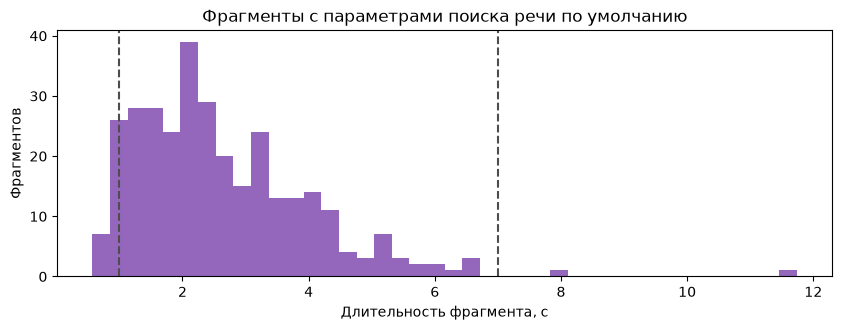

In [6]:
def durations(transcript):
    return pd.Series([s.end - s.start for s in transcript.segments])


fig, ax = plt.subplots(figsize=(10, 3.2))
ax.hist(durations(result), bins=40, color="tab:purple")
for limit in (1, 7):
    ax.axvline(limit, color="0.3", linestyle="--")
ax.set_xlabel("Длительность фрагмента, с")
ax.set_ylabel("Фрагментов")
ax.set_title("Фрагменты с параметрами поиска речи по умолчанию")
plt.show()

## Параметры поиска речи под субтитры

`min_silence_duration_ms` задает, какая пауза разделяет фрагменты: чем она больше, тем длиннее фрагменты и меньше коротких. `max_speech_duration_s` режет слишком длинные. Ниже - первые 5 минут записи с разными параметрами (в команде - `--min-silence-ms` и `--max-speech-s`): чтобы сравнить варианты, не нужно распознавать запись целиком.

In [7]:
variants = {
    "по умолчанию": VadOptions(),
    "паузы от 300 мс": VadOptions(min_silence_duration_ms=300),
    "паузы от 300 мс, до 7 с": VadOptions(min_silence_duration_ms=300, max_speech_duration_s=7),
    "паузы от 500 мс, до 7 с": VadOptions(min_silence_duration_ms=500, max_speech_duration_s=7),
}
part = Audio(audio.samples[: 5 * 60 * audio.sample_rate], audio.sample_rate)
rows = []
for name, vad in variants.items():
    lengths = durations(Transcriber(vad=vad).transcribe_audio(part))
    rows.append(
        {
            "Параметры": name,
            "Фрагментов": len(lengths),
            "Медиана, с": lengths.median(),
            "Короче 1 с": (lengths < 1).mean(),
            "Длиннее 7 с": (lengths > 7).mean(),
        }
    )
pd.DataFrame(rows).round(2)

,Параметры,Фрагментов,"Медиана, с",Короче 1 с,Длиннее 7 с
0,по умолчанию,94,2.32,0.04,0.00
1,паузы от 300 мс,55,3.77,0.02,0.18
2,"паузы от 300 мс, до 7 с",68,3.52,0.01,0.00
3,"паузы от 500 мс, до 7 с",60,4.57,0.02,0.00


Те же параметры в команде:

``` bash
stt-ru transcribe dubrovsky_01.mp3 -o subtitles/ -f srt,vtt --min-silence-ms 300 --max-speech-s 7
```